# Predicting U.S. Domestic Flight Arrival Delays (Q1 2025)
**Module:** 6COSC017C-n Machine Learning and Data Analytics — Coursework 1

**Question.** Using only information that is available *before departure*, can we estimate the probability that a U.S. domestic flight will arrive **15 minutes or more late**? This is the U.S. DOT's official definition of a delayed flight (`ARR_DEL15`).

**Data sources (joined in Section 1):**
1. U.S. Bureau of Transportation Statistics (BTS), *Reporting Carrier On-Time Performance* — January, February and March 2025 (three monthly files). Public-domain U.S. Government data.
2. OurAirports `airports.csv` — airport coordinates, elevation, state and size. Public domain.
3. BTS carrier-code lookup table (`L_UNIQUE_CARRIERS`) — carrier names.

**Notebook structure:** 1 Load · 2 EDA · 3 Data preparation · 4 Model training & tuning · 5 Evaluation on the held-out test set · 6 Save artefacts for the Streamlit app.

In [1]:
# --- Setup -------------------------------------------------------------------
import sys, json, time, warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from src.features import (load_flights, load_airports, clean_flights, join_airports,
                          add_schedule_features, add_lag_features, temporal_split,
                          CARRIER_NAMES, TARGET, NUMERIC_FEATURES, LOW_CARD_CATEGORICAL,
                          HIGH_CARD_CATEGORICAL, ALL_FEATURES, LAG_FEATURES, RAW_DIR, EXT_DIR)
from src.modeling import make_pipeline, make_preprocessor, evaluate, best_f1_threshold, RANDOM_STATE

FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
MODELS = ROOT / "models"; MODELS.mkdir(exist_ok=True)
PROC = ROOT / "data" / "processed"; PROC.mkdir(parents=True, exist_ok=True)

np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight"})
pd.set_option("display.max_columns", 60); pd.set_option("display.width", 160)

def savefig(name):
    plt.savefig(FIG / f"{name}.png"); plt.show()

## 1. Data loading
### 1.1 Flight records (three monthly files)
Each monthly BTS file has the same 11 columns, so they are **stacked vertically** (`concat`). A `SOURCE_FILE` column records where every row came from so the union can be audited.

In [2]:
raw = load_flights(RAW_DIR)
per_file = raw["SOURCE_FILE"].value_counts().reindex(["January", "February", "March"])
print(per_file.to_string())
assert per_file.sum() == len(raw), "row count after concat must equal the sum of the files"
print(f"\nCombined shape: {raw.shape}")
raw.head()

SOURCE_FILE
January     539747
February    504884
March       600872

Combined shape: (1645503, 12)


,FL_DATE,OP_UNIQUE_CARRIER,ORIGIN,DEST,CRS_DEP_TIME,CRS_ARR_TIME,ARR_DELAY,ARR_DEL15,CANCELLED,DIVERTED,DISTANCE,SOURCE_FILE
0,1/1/2025 12:00:00 AM,AA,ABQ,DFW,500,754,-21.0,0.0,0.0,0.0,569.0,January
1,1/1/2025 12:00:00 AM,AA,ABQ,DFW,555,849,-17.0,0.0,0.0,0.0,569.0,January
2,1/1/2025 12:00:00 AM,AA,ABQ,DFW,820,1114,-22.0,0.0,0.0,0.0,569.0,January
3,1/1/2025 12:00:00 AM,AA,ABQ,DFW,1032,1323,-23.0,0.0,0.0,0.0,569.0,January
4,1/1/2025 12:00:00 AM,AA,ABQ,DFW,1700,1948,17.0,1.0,0.0,0.0,569.0,January


### 1.2 Airport metadata (second source) and the join key problem
Flights reference airports by 3-letter IATA code. Checking every BTS code against OurAirports shows which codes have no match **before** joining, so that a left join does not silently create missing values.

In [3]:
airports_all = pd.read_csv(EXT_DIR / "airports.csv", low_memory=False)
bts_codes = sorted(set(raw.ORIGIN) | set(raw.DEST))
unmatched = sorted(set(bts_codes) - set(airports_all.iata_code.dropna()))
print(f"Airport codes in BTS data: {len(bts_codes)}; unmatched in OurAirports: {unmatched}")
airports_all.loc[airports_all.ident == "KPBI", ["ident", "iata_code", "name", "municipality", "keywords"]]

Airport codes in BTS data: 333; unmatched in OurAirports: ['PBI']


,ident,iata_code,name,municipality,keywords
41326,KPBI,DJT,President Donald J. Trump International Airport,West Palm Beach,"PBI, KPBI, MFW, South Florida"


`PBI` (Palm Beach International) is missing because OurAirports has since re-coded the airport (`DJT`); its old code survives only in the `keywords` field. Joining on IATA would leave 18,463 flights with no airport attributes. The fix is to match it on its stable ICAO identifier `KPBI` (see `IATA_FIXES` in `src/features.py`). After the fix, every code matches.

In [4]:
airports = load_airports(EXT_DIR / "airports.csv", codes=bts_codes)
print(f"Matched airports: {airports.IATA.nunique()} / {len(bts_codes)}")
airports.head()

Matched airports: 333 / 333


,IATA,AIRPORT_NAME,LAT,LON,ELEV,STATE,IS_LARGE
0,ABE,Lehigh Valley International Airport,40.651773,-75.442797,393.0,PA,0
1,ABI,Abilene Regional Airport,32.411301,-99.681900,1791.0,TX,0
2,ABQ,Albuquerque International Sunport,35.039976,-106.608925,5355.0,NM,1
3,ABR,Aberdeen Regional Airport,45.449100,-98.421799,1302.0,SD,0
4,ABY,Southwest Georgia Regional Airport,31.532946,-84.196215,197.0,GA,0


### 1.3 Joining
The join is a **many-to-one left join**, done twice (origin and destination). `validate="many_to_one"` makes pandas raise an error if an airport appeared twice in the lookup (which would duplicate flights), and the row count is asserted unchanged. Carrier names are mapped from the BTS lookup table.

In [5]:
clean, clean_log = clean_flights(raw)          # cleaning is explained in Section 3
flights = join_airports(clean, airports)
flights["CARRIER_NAME"] = flights["OP_UNIQUE_CARRIER"].map(CARRIER_NAMES)
print("Rows before/after join:", len(clean), len(flights))
print("Missing values created by the joins:\n",
      flights[["ORIGIN_LAT", "DEST_LAT", "CARRIER_NAME"]].isna().sum().to_string())

Rows before/after join: 1645500 1645500
Missing values created by the joins:
 ORIGIN_LAT      0
DEST_LAT        0
CARRIER_NAME    0


## 2. Exploratory Data Analysis
### 2.1 Shape, types and missing values
Knowing the types tells us which columns need parsing (`FL_DATE` is text, times are `HHMM` integers, flags are stored as floats). Knowing where values are missing, and *why*, decides how they are treated.

In [6]:
print("Shape:", raw.shape)
info = pd.DataFrame({"dtype": raw.dtypes.astype(str),
                     "n_unique": raw.nunique(),
                     "missing": raw.isna().sum(),
                     "missing_%": (raw.isna().mean() * 100).round(2)})
info

Shape: (1645503, 12)


,dtype,n_unique,missing,missing_%
FL_DATE,str,90,0,0.00
OP_UNIQUE_CARRIER,str,14,0,0.00
ORIGIN,str,333,0,0.00
DEST,str,333,0,0.00
CRS_DEP_TIME,int32,1284,0,0.00
CRS_ARR_TIME,int32,1380,0,0.00
ARR_DELAY,float64,1473,34457,2.09
ARR_DEL15,float64,2,34457,2.09
CANCELLED,float64,2,0,0.00
DIVERTED,float64,2,0,0.00


In [7]:
# Are the missing ARR_DELAY values random? Cross-tabulate against the status flags.
miss = raw["ARR_DELAY"].isna()
pd.crosstab(miss, [raw["CANCELLED"], raw["DIVERTED"]], rownames=["ARR_DELAY missing"],
            colnames=["CANCELLED", "DIVERTED"])

CANCELLED              0.0          1.0
DIVERTED               0.0   1.0    0.0
ARR_DELAY missing                      
False              1611046     0      0
True                     0  3817  30640

**Finding.** All 34,457 missing `ARR_DELAY`/`ARR_DEL15` values belong to cancelled (30,640) or diverted (3,817) flights. The values are *structurally* missing: these flights never arrived at their scheduled destination, so an arrival delay does not exist. Imputing them would be wrong. Section 3 removes them from the target population.

### 2.2 Summary statistics (central tendency and dispersion)
Mean, median, variance and standard deviation describe the typical value and spread. Skewness and kurtosis show whether the mean is a fair summary or is pulled by a long tail.

In [8]:
num_cols = ["CRS_DEP_TIME", "CRS_ARR_TIME", "DISTANCE", "ARR_DELAY", "ARR_DEL15", "CANCELLED", "DIVERTED"]
desc = raw[num_cols].describe().T
desc["median"] = raw[num_cols].median()
desc["variance"] = raw[num_cols].var()
desc["skewness"] = raw[num_cols].skew()
desc["kurtosis"] = raw[num_cols].kurt()
desc.round(3)

,count,mean,std,min,25%,50%,75%,max,median,variance,skewness,kurtosis
CRS_DEP_TIME,1645503.0,1322.654,488.459,1.0,905.0,1316.0,1733.0,2359.0,1316.0,238591.708,0.090,-1.072
CRS_ARR_TIME,1645503.0,1498.978,514.831,1.0,1110.0,1523.0,1929.0,2359.0,1523.0,265051.092,-0.291,-0.474
DISTANCE,1645503.0,846.612,597.373,31.0,404.0,718.0,1085.0,5095.0,718.0,356854.814,1.475,3.108
ARR_DELAY,1611046.0,4.984,57.137,-91.0,-17.0,-8.0,8.0,3407.0,-8.0,3264.611,10.283,213.768
ARR_DEL15,1611046.0,0.197,0.398,0.0,0.0,0.0,0.0,1.0,0.0,0.158,1.524,0.323
CANCELLED,1645503.0,0.019,0.135,0.0,0.0,0.0,0.0,1.0,0.0,0.018,7.122,48.724
DIVERTED,1645503.0,0.002,0.048,0.0,0.0,0.0,0.0,1.0,0.0,0.002,20.691,426.102


In [9]:
cat_summary = pd.DataFrame({c: [raw[c].nunique(), raw[c].mode()[0], raw[c].value_counts().iloc[0]]
                            for c in ["OP_UNIQUE_CARRIER", "ORIGIN", "DEST"]},
                           index=["unique", "most frequent", "frequency"]).T
cat_summary

,unique,most frequent,frequency
OP_UNIQUE_CARRIER,14,WN,327938
ORIGIN,333,DFW,75088
DEST,333,DFW,75069


**Interpretation.** `ARR_DELAY` has mean ≈ 5.0 min but median −8 min: the typical flight arrives early. Skewness ≈ 10 and a maximum of 3,407 min show an extreme right tail, so the mean overstates the typical delay. This supports modelling the **binary** `ARR_DEL15` outcome, which the tail cannot distort, rather than regressing raw minutes. `DISTANCE` is also right-skewed (long Hawaii/Alaska routes), which motivates a log transform.

### 2.3 Target variable

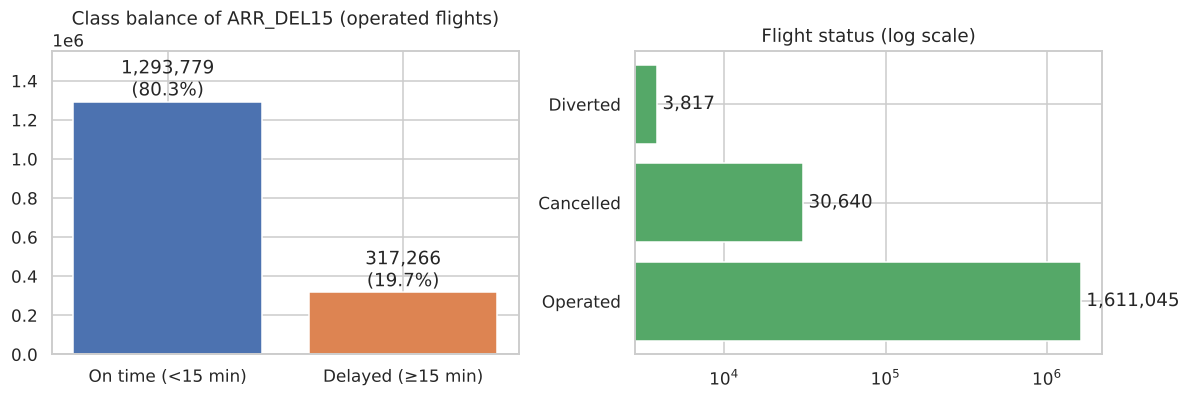

In [10]:
op_raw = flights[(flights.CANCELLED == 0) & (flights.DIVERTED == 0)]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
vc = op_raw[TARGET].value_counts().sort_index()
ax[0].bar(["On time (<15 min)", "Delayed (≥15 min)"], vc.values, color=["#4C72B0", "#DD8452"])
for i, v in enumerate(vc.values):
    ax[0].text(i, v, f"{v:,}\n({v/vc.sum():.1%})", ha="center", va="bottom")
ax[0].set_ylim(0, vc.max() * 1.2); ax[0].set_title("Class balance of ARR_DEL15 (operated flights)")
status = pd.Series({"Operated": len(op_raw), "Cancelled": int(raw.CANCELLED.sum()), "Diverted": int(raw.DIVERTED.sum())})
ax[1].barh(status.index, status.values, color="#55A868"); ax[1].set_xscale("log")
ax[1].set_title("Flight status (log scale)")
for i, v in enumerate(status.values): ax[1].text(v, i, f" {v:,}", va="center")
plt.tight_layout(); savefig("fig01_target_distribution")

About **19.7 %** of operated flights are delayed, so the classes are imbalanced (≈ 1 : 4). Accuracy alone is therefore misleading: predicting "on time" for every flight scores 80 %. Section 4 uses ROC-AUC, PR-AUC, recall/TPR, specificity/TNR, precision and F1 instead.

### 2.4 Distribution of arrival delay (histogram and box plot)

/tmp/ipykernel_434/2437724849.py:6: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax[1].boxplot(d, vert=False, flierprops=dict(markersize=1, alpha=.2)); ax[1].set_xscale("symlog")


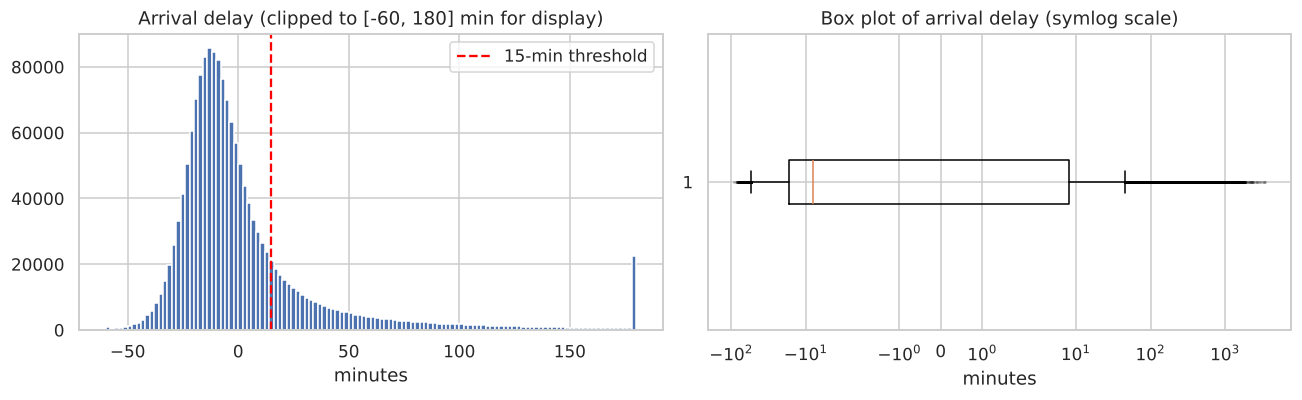

Q1=-17.0, Q3=8.0, IQR=25.0, upper fence=45.5; share above fence: 9.02%


In [11]:
d = op_raw["ARR_DELAY"]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].hist(d.clip(-60, 180), bins=120, color="#4C72B0")
ax[0].axvline(15, color="red", ls="--", label="15-min threshold"); ax[0].legend()
ax[0].set_title("Arrival delay (clipped to [-60, 180] min for display)"); ax[0].set_xlabel("minutes")
ax[1].boxplot(d, vert=False, flierprops=dict(markersize=1, alpha=.2)); ax[1].set_xscale("symlog")
ax[1].set_title("Box plot of arrival delay (symlog scale)"); ax[1].set_xlabel("minutes")
plt.tight_layout(); savefig("fig02_arr_delay_distribution")
q1, q3 = d.quantile([.25, .75]); iqr = q3 - q1
print(f"Q1={q1}, Q3={q3}, IQR={iqr}, upper fence={q3+1.5*iqr}; share above fence: {(d > q3+1.5*iqr).mean():.2%}")

### 2.5 Delay rate by carrier, hour, weekday and day
Grouped delay rates show which categorical and temporal variables carry signal. Each bar is a conditional mean of the target.

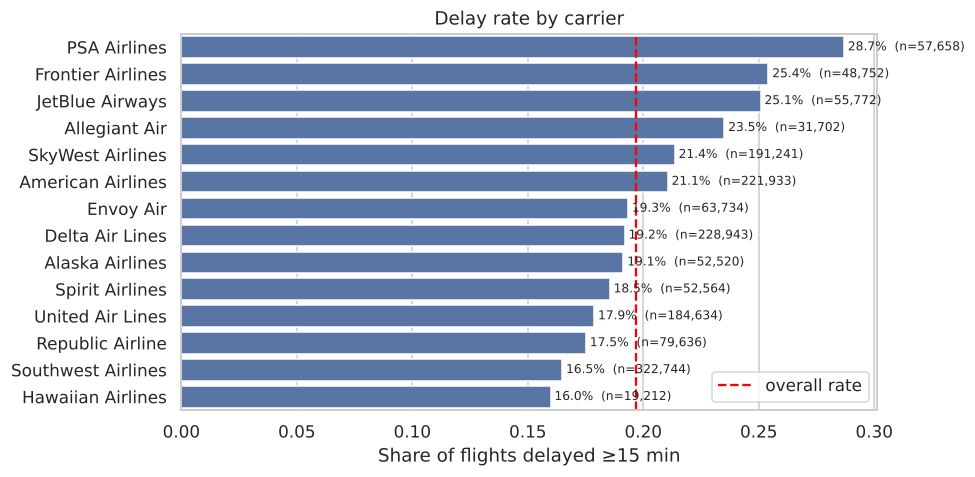

Chi-square = 8,859, dof = 13, p = 0.00e+00, Cramér's V = 0.074


In [12]:
carrier = (op_raw.groupby("CARRIER_NAME")[TARGET].agg(["mean", "size"])
           .sort_values("mean", ascending=False))
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(x=carrier["mean"], y=carrier.index, color="#4C72B0", ax=ax)
ax.axvline(op_raw[TARGET].mean(), color="red", ls="--", label="overall rate"); ax.legend()
ax.set_xlabel("Share of flights delayed ≥15 min"); ax.set_ylabel(""); ax.set_title("Delay rate by carrier")
for i, (m, n) in enumerate(zip(carrier["mean"], carrier["size"])):
    ax.text(m, i, f" {m:.1%}  (n={n:,})", va="center", fontsize=8)
plt.tight_layout(); savefig("fig03_delay_by_carrier")

# chi-square test: is delay status independent of carrier?
ct = pd.crosstab(op_raw["OP_UNIQUE_CARRIER"], op_raw[TARGET])
chi2, p, dof, _ = stats.chi2_contingency(ct)
cramers_v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
print(f"Chi-square = {chi2:,.0f}, dof = {dof}, p = {p:.2e}, Cramér's V = {cramers_v:.3f}")

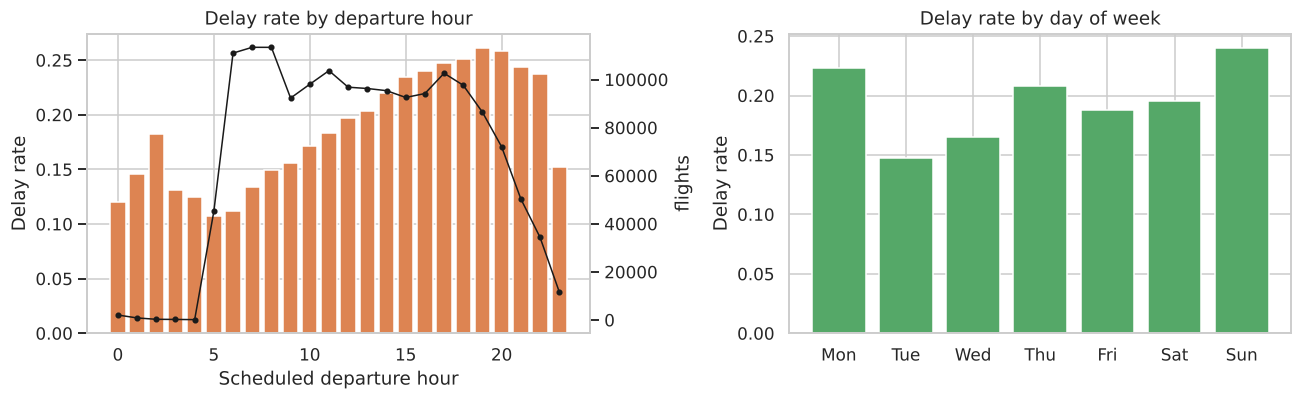

In [13]:
feat_eda = add_schedule_features(flights)
op_eda = feat_eda[(feat_eda.CANCELLED == 0) & (feat_eda.DIVERTED == 0)]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
h = op_eda.groupby("DEP_HOUR")[TARGET].agg(["mean", "size"])
ax[0].bar(h.index, h["mean"], color="#DD8452"); ax2 = ax[0].twinx()
ax2.plot(h.index, h["size"], color="k", lw=1, marker=".", label="flights"); ax2.set_ylabel("flights"); ax2.grid(False)
ax[0].set_xlabel("Scheduled departure hour"); ax[0].set_ylabel("Delay rate"); ax[0].set_title("Delay rate by departure hour")
dow = op_eda.groupby("DAY_OF_WEEK")[TARGET].mean()
ax[1].bar(["Mon","Tue","Wed","Thu","Fri","Sat","Sun"], dow.values, color="#55A868")
ax[1].set_title("Delay rate by day of week"); ax[1].set_ylabel("Delay rate")
plt.tight_layout(); savefig("fig04_delay_by_hour_weekday")

**Finding.** The delay rate is lowest for first-wave departures (≈ 11 % at 05:00–06:59) and climbs through the day to ≈ 25–26 % for 17:00–20:00 departures. Delays **propagate**: an aircraft late on its first leg is later on every later leg, and early-morning flights start with a fresh aircraft. This is the strongest schedule signal, and it motivates the cyclical hour features in Section 3.

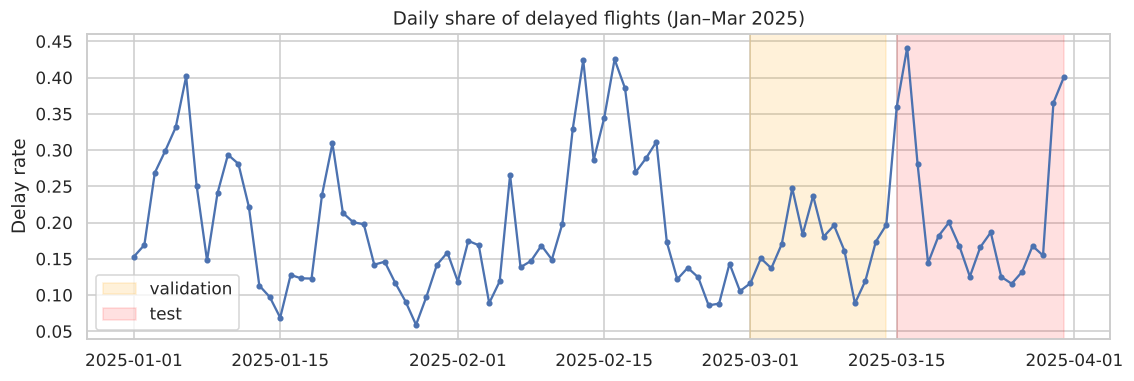

count    90.000
mean      0.196
std       0.092
min       0.059
25%       0.126
50%       0.168
75%       0.250
max       0.441
Lag-1 autocorrelation of the daily delay rate: 0.702


In [14]:
daily = op_eda.groupby("FL_DATE")[TARGET].mean()
fig, ax = plt.subplots(figsize=(12, 3.6))
ax.plot(daily.index, daily.values, marker=".", color="#4C72B0")
ax.axvspan(pd.Timestamp("2025-03-01"), pd.Timestamp("2025-03-14"), color="orange", alpha=.15, label="validation")
ax.axvspan(pd.Timestamp("2025-03-15"), pd.Timestamp("2025-03-31"), color="red", alpha=.12, label="test")
ax.set_title("Daily share of delayed flights (Jan–Mar 2025)"); ax.set_ylabel("Delay rate"); ax.legend()
savefig("fig05_daily_delay_rate")
print(daily.describe().round(3).to_string())
print("Lag-1 autocorrelation of the daily delay rate:", round(daily.autocorr(1), 3))

**Finding.** The daily delay rate ranges from about 6 % to 44 %, far more than any carrier or hour effect. Spikes match weather events such as winter storms. The series is autocorrelated: a bad day tends to be followed by another bad day. Two consequences:
1. A **random** train/test split would put flights from the same storm day in both sets and inflate the scores. A **temporal** split is required (Section 3.7), and its effect is measured in Section 5.6.
2. **Yesterday's** disruption rate is a legitimate predictor, because it is known before today's flights depart. This motivates the lag features.

### 2.6 Geography (scatter of airports)

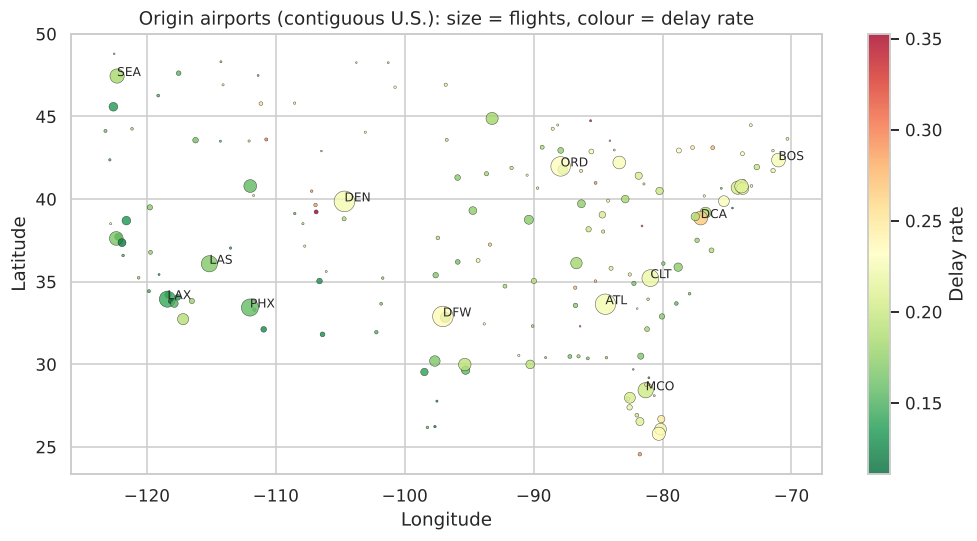

In [15]:
ap = (op_eda.groupby("ORIGIN").agg(rate=(TARGET, "mean"), n=(TARGET, "size"),
                                   lat=("ORIGIN_LAT", "first"), lon=("ORIGIN_LON", "first"))
      .query("n >= 500 and lon < -60 and lon > -130 and lat > 20"))
fig, ax = plt.subplots(figsize=(11, 5.2))
sc = ax.scatter(ap.lon, ap.lat, s=ap.n / 400, c=ap.rate, cmap="RdYlGn_r", alpha=.8, edgecolor="k", lw=.3)
plt.colorbar(sc, label="Delay rate"); ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
for code_, r in ap.nlargest(12, "n").iterrows(): ax.annotate(code_, (r.lon, r.lat), fontsize=8)
ax.set_title("Origin airports (contiguous U.S.): size = flights, colour = delay rate")
savefig("fig06_airport_map")

### 2.7 Correlation analysis
Pearson correlation measures linear association and Spearman measures monotonic association. Both are computed between the numeric engineered features and the target. A correlation with a binary target is a point-biserial correlation. Strongly inter-correlated predictors (multicollinearity) inflate the coefficient variance in logistic regression.

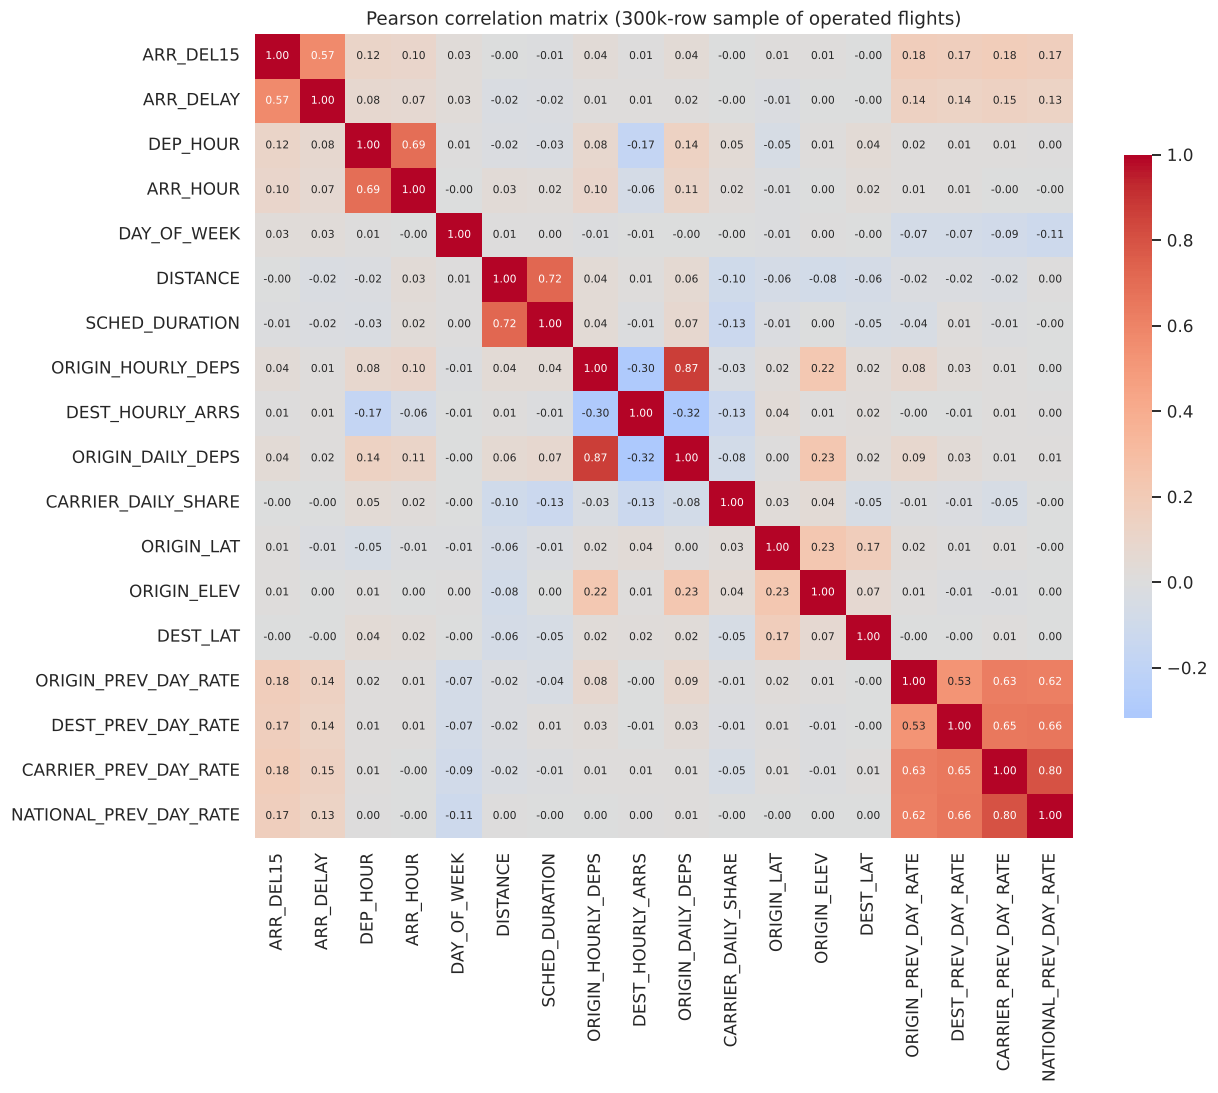

,pearson_vs_target,spearman_vs_target
CARRIER_PREV_DAY_RATE,0.185,0.180
ORIGIN_PREV_DAY_RATE,0.182,0.176
DEST_PREV_DAY_RATE,0.171,0.170
NATIONAL_PREV_DAY_RATE,0.167,0.160
DEP_HOUR,0.116,0.118
ARR_HOUR,0.101,0.110
ORIGIN_DAILY_DEPS,0.040,0.034
ORIGIN_HOURLY_DEPS,0.035,0.032
DAY_OF_WEEK,0.026,0.026
SCHED_DURATION,-0.012,-0.002


In [16]:
full_eda = add_lag_features(feat_eda)
op_corr = full_eda[(full_eda.CANCELLED == 0) & (full_eda.DIVERTED == 0)]
corr_cols = ["ARR_DEL15", "ARR_DELAY", "DEP_HOUR", "ARR_HOUR", "DAY_OF_WEEK", "DISTANCE", "SCHED_DURATION",
             "ORIGIN_HOURLY_DEPS", "DEST_HOURLY_ARRS", "ORIGIN_DAILY_DEPS", "CARRIER_DAILY_SHARE",
             "ORIGIN_LAT", "ORIGIN_ELEV", "DEST_LAT", "ORIGIN_PREV_DAY_RATE", "DEST_PREV_DAY_RATE",
             "CARRIER_PREV_DAY_RATE", "NATIONAL_PREV_DAY_RATE"]
sample = op_corr[corr_cols].sample(300_000, random_state=RANDOM_STATE)
pear = sample.corr(method="pearson")
fig, ax = plt.subplots(figsize=(12, 9.5))
sns.heatmap(pear, cmap="coolwarm", center=0, annot=True, fmt=".2f", annot_kws={"size": 7}, ax=ax,
            cbar_kws={"shrink": .7})
ax.set_title("Pearson correlation matrix (300k-row sample of operated flights)")
savefig("fig07_correlation_matrix")
spear = sample.corr(method="spearman")["ARR_DEL15"]
pd.DataFrame({"pearson_vs_target": pear["ARR_DEL15"], "spearman_vs_target": spear}).drop(
    ["ARR_DEL15", "ARR_DELAY"]).sort_values("pearson_vs_target", key=abs, ascending=False).round(3)

**Findings.**
* The strongest single correlates of `ARR_DEL15` are the **previous-day disruption rates** (r ≈ 0.17–0.19) and the **departure hour** (r ≈ 0.12). All correlations are weak, which is expected for flight delays: much of the variance comes from same-day weather and knock-on effects that are not in the data. The models should therefore have modest discriminative power.
* `DISTANCE` and `SCHED_DURATION` are strongly correlated (r ≈ 0.72; not higher because local clock times include time-zone shifts), as are `DEP_HOUR`/`ARR_HOUR` (r ≈ 0.69) and `ORIGIN_DAILY_DEPS`/`ORIGIN_HOURLY_DEPS` (r ≈ 0.87). The tree models are unaffected. For logistic regression, L2 regularisation (tuned through `C`) stabilises the coefficients.
* `ARR_DELAY` is shown for reference only. It *is* the outcome, so it is never used as a feature (leakage).

/tmp/ipykernel_434/3711515792.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(["On time", "Delayed"]); ax.set_xlabel("")


/tmp/ipykernel_434/3711515792.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(["On time", "Delayed"]); ax.set_xlabel("")


/tmp/ipykernel_434/3711515792.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(["On time", "Delayed"]); ax.set_xlabel("")


/tmp/ipykernel_434/3711515792.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(["On time", "Delayed"]); ax.set_xlabel("")


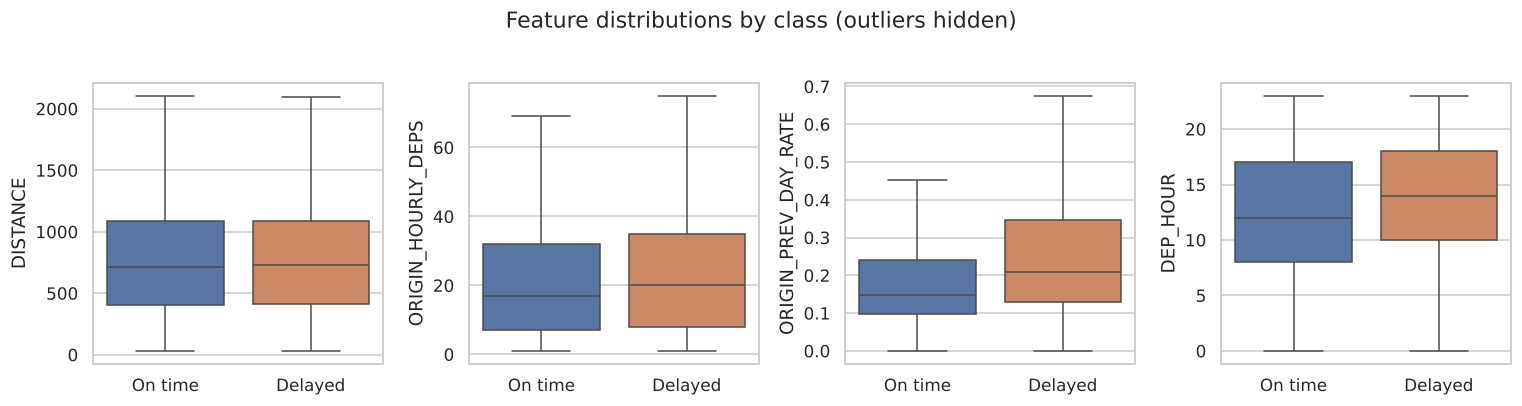

In [17]:
# Box plots of key numeric features by class
fig, axes = plt.subplots(1, 4, figsize=(14, 3.6))
for ax, c in zip(axes, ["DISTANCE", "ORIGIN_HOURLY_DEPS", "ORIGIN_PREV_DAY_RATE", "DEP_HOUR"]):
    sns.boxplot(data=sample, x="ARR_DEL15", y=c, ax=ax, showfliers=False, palette=["#4C72B0", "#DD8452"])
    ax.set_xticklabels(["On time", "Delayed"]); ax.set_xlabel("")
fig.suptitle("Feature distributions by class (outliers hidden)", y=1.02)
plt.tight_layout(); savefig("fig08_boxplots_by_class")

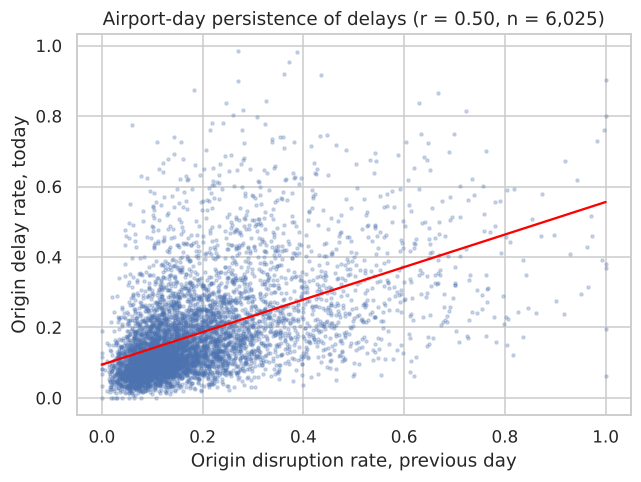

In [18]:
# Scatter: yesterday's origin disruption rate vs today's origin delay rate (airport-day level)
ad = (op_corr.groupby(["ORIGIN", "FL_DATE"]).agg(today=(TARGET, "mean"), prev=("ORIGIN_PREV_DAY_RATE", "first"),
                                                 n=(TARGET, "size")).query("n >= 50").dropna())
r, p = stats.pearsonr(ad.prev, ad.today)
fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.scatter(ad.prev, ad.today, s=4, alpha=.25)
m, b = np.polyfit(ad.prev, ad.today, 1); xs = np.linspace(0, 1, 50); ax.plot(xs, m*xs + b, color="red")
ax.set_xlabel("Origin disruption rate, previous day"); ax.set_ylabel("Origin delay rate, today")
ax.set_title(f"Airport-day persistence of delays (r = {r:.2f}, n = {len(ad):,})")
savefig("fig09_lag_scatter")

## 3. Data preparation
### 3.1 Correcting erroneous data
`clean_flights()` runs explicit validity checks and logs each one. It has already been applied in Section 1.3.

In [19]:
pd.Series(clean_log, name="count").to_frame()

,count
rows_in,1645503
exact_duplicates_removed,3
invalid_clock_times_removed,0
impossible_records_removed,0
target_inconsistencies_corrected,0
unexplained_missing_target_removed,0
rows_out,1645500


* **Exact duplicates (3 removed).** Identical rows across all columns are double-reported records. Keeping them would give those flights double weight.
* **Clock validity.** `HHMM` values with minutes > 59 or hours > 24 would corrupt the hour features. None were found, but the check stays in the pipeline for new data. `2400` is mapped to `0000`.
* **Impossible combinations.** These are origin = destination, non-positive distance, and a flight both cancelled and diverted. None were found.
* **Target consistency.** `ARR_DEL15` is re-derived from `ARR_DELAY ≥ 15` and compared with the reported value. There were zero mismatches.
* **Join-key error.** PBI was re-coded (see Section 1.2) and is corrected through its ICAO code.
* 428 rows share date, carrier, route and scheduled departure time, but the file has no flight number. These can be genuine separate flights (e.g., a shuttle and an extra section), so they are **not** treated as duplicates.

### 3.2 Missing values
| Source of missingness | Rows | Treatment | Reason |
|---|---|---|---|
| `ARR_DELAY`/`ARR_DEL15` for cancelled/diverted flights | 34,455 | Excluded from the modelling population | Structurally missing: arrival delay is undefined. Predicting cancellations is a different problem. |
| Airport attributes after join | 0 (18,463 flights before the PBI fix) | Fixed at source | Mismatched key, not truly unknown |
| Lag features on 1 Jan and on an airport's first active day | ≈1 % | `SimpleImputer(median)` inside the pipeline | No history exists. The median is robust to the skewed rates, and fitting the imputer on training folds only avoids leakage. |
| Unseen categories at inference (e.g., a new route in the app) | — | `handle_unknown="ignore"` / encoder falls back to the global mean | Robust deployment |

In [20]:
full = full_eda  # schedule + lag features already built in Section 2.7
del feat_eda, op_eda, op_corr, sample; import gc; gc.collect()
data = full[(full.CANCELLED == 0) & (full.DIVERTED == 0)].copy()
data[TARGET] = data[TARGET].astype(int)
print(f"Modelling rows: {len(data):,}")
print("Missing values in model features:\n", data[ALL_FEATURES].isna().sum()[lambda s: s > 0].to_string())

Modelling rows: 1,611,045
Missing values in model features:
 ORIGIN_PREV_DAY_RATE      17336
DEST_PREV_DAY_RATE        17360
CARRIER_PREV_DAY_RATE     16771
NATIONAL_PREV_DAY_RATE    16771


### 3.3 Outliers
Arrival delays above the IQR fence (≈ 45 min) are **genuine** events such as storms and crew time-outs, not recording errors. They are exactly the cases the model should learn to flag. Because the target is the binary `ARR_DEL15`, extreme minutes cannot distort the loss, so the outliers are **kept**. Long distances (HNL, ANC routes) are real and are compressed with `log1p` rather than removed. Congestion counts are right-skewed and are also log-transformed.

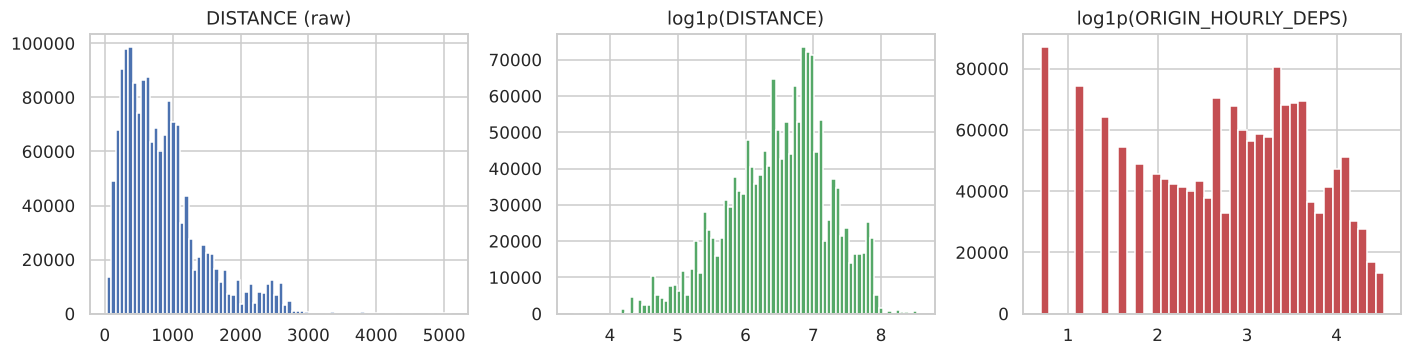

Skewness raw vs log distance: 1.47 -0.39


In [21]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
ax[0].hist(data.DISTANCE, bins=80); ax[0].set_title("DISTANCE (raw)")
ax[1].hist(data.LOG_DISTANCE, bins=80, color="#55A868"); ax[1].set_title("log1p(DISTANCE)")
ax[2].hist(data.LOG_ORIGIN_HOURLY_DEPS, bins=40, color="#C44E52"); ax[2].set_title("log1p(ORIGIN_HOURLY_DEPS)")
plt.tight_layout(); savefig("fig10_transformations")
print("Skewness raw vs log distance:", round(data.DISTANCE.skew(), 2), round(data.LOG_DISTANCE.skew(), 2))

### 3.4 Feature engineering
Every feature can be computed **before departure**:

| Group | Features | Rationale |
|---|---|---|
| Clock (cyclical) | `DEP/ARR_HOUR_SIN/COS`, `DEP_TIME_BLOCK` | Sine/cosine encoding places 23:00 next to 00:00. Delay propagation through the day was the strongest pattern in the EDA. |
| Calendar | `DAY_OF_WEEK`, `IS_WEEKEND` | Weekly demand cycle |
| Route geometry | `LOG_DISTANCE`, `SCHED_DURATION`, `OVERNIGHT`, `ROUTE` | Longer flights can absorb delays en route. Overnight (red-eye) operations differ. |
| Congestion | `LOG_ORIGIN_HOURLY_DEPS`, `LOG_DEST_HOURLY_ARRS`, `LOG_ORIGIN_DAILY_DEPS`, `CARRIER_DAILY_SHARE` | Built from the *schedule*, including flights later cancelled, so the values are known in advance. Busy hours queue for runways. Hub carriers can swap aircraft. |
| Airport (joined) | lat/lon, elevation, state, large-hub flag | Northern airports face snow and ice in Q1. Hubs behave differently. |
| Persistence (lag) | `ORIGIN/DEST/CARRIER/NATIONAL_PREV_DAY_RATE` | Yesterday's disruption share (delayed, cancelled or diverted). Multi-day storms and operational meltdowns persist. |

### 3.5 Encoding and scaling
* **Numeric features:** `StandardScaler` (zero mean, unit variance). Logistic regression is optimised by gradient-based solvers and penalised by L2, so unscaled features would converge slowly and be penalised unevenly. Trees are scale-invariant, so scaling is harmless for them.
* **Low-cardinality categories** (14 carriers, 5 time blocks): **one-hot encoding.** This adds few columns and imposes no false ordering.
* **High-cardinality categories** (333 airports, ≈ 5,900 routes, states): **target encoding** with 5-fold cross-fitting and automatic smoothing. One-hot encoding would create about 6,000 sparse columns. Cross-fitting means each training row is encoded with statistics from *other* folds, which prevents the encoder from leaking the row's own label. Smoothing shrinks rare routes towards the global mean.

All of these steps sit inside one scikit-learn `Pipeline`. They are fitted on training data only, and the same fitted object is used by the app (no train/serve skew).

### 3.6 Features deliberately excluded (leakage and distribution-shift checks)
* `ARR_DELAY`, `CANCELLED`, `DIVERTED`: outcomes, never inputs.
* `DAY_OF_MONTH`: lets trees memorise *which specific days* had storms in January and February. That knowledge cannot transfer to March. In prototyping, validation ROC-AUC fell when it was included.
* `DAYS_TO_HOLIDAY`: there are no federal holidays near the 1–31 March period, so the feature is constant (= 14) in validation and test. A model cannot learn anything useful from it for those months.

In [22]:
print("DAYS_TO_HOLIDAY in Jan-Feb:", data.loc[data.MONTH < 3, "DAYS_TO_HOLIDAY"].value_counts().sort_index().head(8).to_dict(), "...")
print("DAYS_TO_HOLIDAY in March :", data.loc[data.MONTH == 3, "DAYS_TO_HOLIDAY"].unique())
print("Features used by the models:", len(ALL_FEATURES)); print(ALL_FEATURES)

DAYS_TO_HOLIDAY in Jan-Feb: {0: 54078, 1: 84691, 2: 82049, 3: 92972, 4: 93508, 5: 80821, 6: 85027, 7: 89583} ...
DAYS_TO_HOLIDAY in March : [12 13 14]
Features used by the models: 32
['DEP_HOUR_SIN', 'DEP_HOUR_COS', 'ARR_HOUR_SIN', 'ARR_HOUR_COS', 'DAY_OF_WEEK', 'IS_WEEKEND', 'LOG_DISTANCE', 'SCHED_DURATION', 'OVERNIGHT', 'LOG_ORIGIN_HOURLY_DEPS', 'LOG_DEST_HOURLY_ARRS', 'LOG_ORIGIN_DAILY_DEPS', 'CARRIER_DAILY_SHARE', 'ORIGIN_LAT', 'ORIGIN_LON', 'ORIGIN_ELEV', 'DEST_LAT', 'DEST_LON', 'DEST_ELEV', 'ORIGIN_IS_LARGE', 'DEST_IS_LARGE', 'ORIGIN_PREV_DAY_RATE', 'DEST_PREV_DAY_RATE', 'CARRIER_PREV_DAY_RATE', 'NATIONAL_PREV_DAY_RATE', 'OP_UNIQUE_CARRIER', 'DEP_TIME_BLOCK', 'ORIGIN', 'DEST', 'ROUTE', 'ORIGIN_STATE', 'DEST_STATE']


### 3.7 Train / validation / test split (temporal)
* **Train:** 1 Jan – 28 Feb 2025 (fit models)
* **Validation:** 1–14 Mar 2025 (hyperparameter tuning and threshold selection)
* **Test:** 15–31 Mar 2025 (touched **once**, for the final comparison)

This mirrors deployment: a model trained on the past predicts the future. It also guarantees that no storm day appears in more than one set.

In [23]:
train, val, test = temporal_split(data)
split_tbl = pd.DataFrame({s: [len(d), d.FL_DATE.min().date(), d.FL_DATE.max().date(), d[TARGET].mean()]
                          for s, d in [("train", train), ("validation", val), ("test", test)]},
                         index=["rows", "from", "to", "delay rate"]).T
split_tbl["share"] = (split_tbl["rows"] / len(data)).astype(float).round(3)
split_tbl

,rows,from,to,delay rate,share
train,1018745,2025-01-01,2025-02-28,0.197529,0.632
validation,263940,2025-03-01,2025-03-14,0.168694,0.164
test,328360,2025-03-15,2025-03-31,0.217776,0.204


In [24]:
X_train, y_train = train[ALL_FEATURES], train[TARGET]
X_val, y_val = val[ALL_FEATURES], val[TARGET]
X_test, y_test = test[ALL_FEATURES], test[TARGET]

# quick look at the transformed design matrix
pre = make_preprocessor().fit(X_train.sample(100_000, random_state=1), y_train.sample(100_000, random_state=1))
print("Transformed feature count:", len(pre.get_feature_names_out()))

Transformed feature count: 49


## 4. Model training and hyperparameter tuning
### 4.1 Algorithms
This is a **supervised binary classification** problem. Four algorithms with different inductive biases are compared against a naive baseline:

| Model | Bias / assumption | Why include it |
|---|---|---|
| Logistic Regression | Log-odds are *linear* in the features; independent observations | Interpretable, calibrated baseline. Shows how much signal is linear. |
| Decision Tree | Axis-aligned piecewise-constant splits; high variance | Captures interactions and is transparent, but prone to overfitting |
| Random Forest | Bagging + feature subsampling averages decorrelated trees | Reduces the tree's variance and is robust to noise |
| LightGBM (gradient boosting) | Sequentially fits trees to residuals (reduces bias); leaf-wise growth | Usually the state of the art for tabular data with mixed feature types |

### 4.2 Tuning protocol
`RandomizedSearchCV` with a `PredefinedSplit`: candidates are fitted on a 300k-row random sample of the training period and scored on a 100k-row sample of the **validation** period. Ordinary k-fold CV would mix days and leak weather across folds. **Average precision (PR-AUC)** is the selection metric because it focuses on the minority (delayed) class and does not depend on a threshold. The best configuration is then refitted on the **full** training set.

In [25]:
from sklearn.model_selection import RandomizedSearchCV, PredefinedSplit
from sklearn.dummy import DummyClassifier
from scipy.stats import loguniform, randint, uniform

tr_s = train.sample(300_000, random_state=RANDOM_STATE)
va_s = val.sample(100_000, random_state=RANDOM_STATE)
X_search = pd.concat([tr_s[ALL_FEATURES], va_s[ALL_FEATURES]])
y_search = pd.concat([tr_s[TARGET], va_s[TARGET]])
ps = PredefinedSplit(np.r_[np.full(len(tr_s), -1), np.zeros(len(va_s))])

search_spaces = {
    "Logistic Regression": ({"model__C": loguniform(1e-3, 10), "model__class_weight": [None, "balanced"]}, 10),
    "Decision Tree": ({"model__max_depth": randint(4, 21), "model__min_samples_leaf": [50, 100, 200, 500, 1000, 2000],
                       "model__criterion": ["gini", "entropy"], "model__class_weight": [None, "balanced"]}, 15),
    "Random Forest": ({"model__n_estimators": [100, 200], "model__max_depth": [10, 14, 18, 22],
                       "model__min_samples_leaf": [20, 50, 100, 200], "model__max_features": ["sqrt", 0.3, 0.5],
                       "model__max_samples": [0.1, 0.2, 0.3], "model__class_weight": [None, "balanced_subsample"]}, 10),
    "LightGBM": ({"model__n_estimators": randint(200, 900), "model__learning_rate": loguniform(0.02, 0.15),
                  "model__num_leaves": randint(15, 128), "model__min_child_samples": randint(100, 2000),
                  "model__subsample": uniform(0.6, 0.4), "model__subsample_freq": [1],
                  "model__colsample_bytree": uniform(0.5, 0.5), "model__reg_lambda": loguniform(1e-3, 10)}, 15),
}
search_results, best_params = {}, {}
for name, (space, n_iter) in search_spaces.items():
    t0 = time.time()
    rs = RandomizedSearchCV(make_pipeline(name), space, n_iter=n_iter, cv=ps, scoring="average_precision",
                            refit=False, random_state=RANDOM_STATE, n_jobs=1)
    rs.fit(X_search, y_search)
    res = pd.DataFrame(rs.cv_results_).sort_values("rank_test_score")
    search_results[name] = res
    best_params[name] = {k.replace("model__", ""): v for k, v in rs.best_params_.items()}
    print(f"{name:20s} best val PR-AUC = {rs.best_score_:.4f}  ({time.time()-t0:.0f}s)  {best_params[name]}")

Logistic Regression  best val PR-AUC = 0.2431  (40s)  {'C': np.float64(0.02161894240657444), 'class_weight': 'balanced'}


Decision Tree        best val PR-AUC = 0.2255  (80s)  {'class_weight': 'balanced', 'criterion': 'entropy', 'max_depth': 18, 'min_samples_leaf': 2000}


Random Forest        best val PR-AUC = 0.2470  (188s)  {'n_estimators': 100, 'min_samples_leaf': 20, 'max_samples': 0.3, 'max_features': 0.3, 'max_depth': 14, 'class_weight': 'balanced_subsample'}


LightGBM             best val PR-AUC = 0.2659  (254s)  {'colsample_bytree': np.float64(0.9711008778424264), 'learning_rate': np.float64(0.062221674590294686), 'min_child_samples': 876, 'n_estimators': 545, 'num_leaves': 67, 'reg_lambda': np.float64(0.008386394780402562), 'subsample': np.float64(0.6964101864104046), 'subsample_freq': 1}


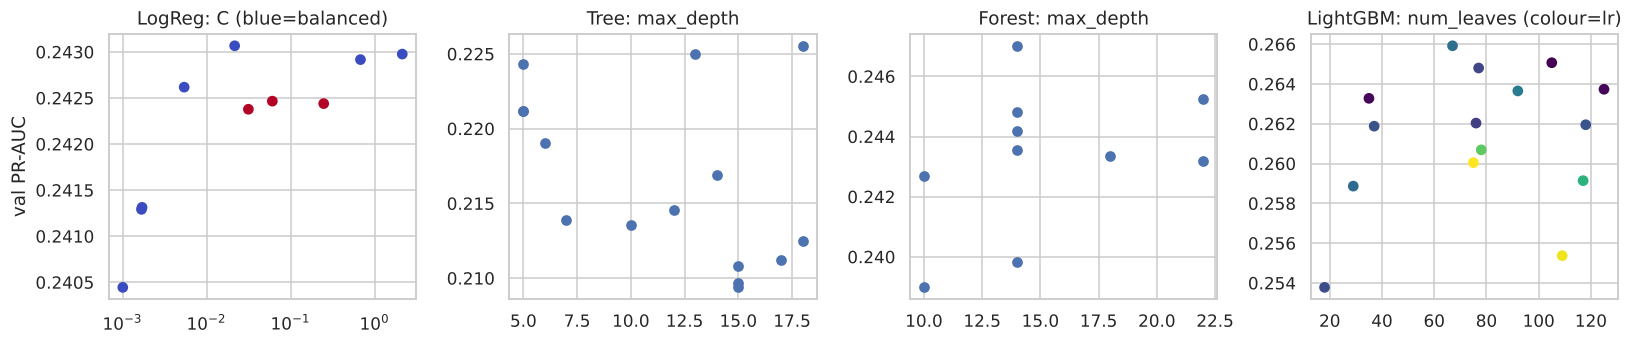

In [26]:
# Sensitivity of validation PR-AUC to key hyperparameters
fig, ax = plt.subplots(1, 4, figsize=(15, 3.3))
r = search_results["Logistic Regression"]; ax[0].scatter(r.param_model__C.astype(float), r.mean_test_score, c=r.param_model__class_weight.isna(), cmap="coolwarm")
ax[0].set_xscale("log"); ax[0].set_title("LogReg: C (blue=balanced)"); ax[0].set_ylabel("val PR-AUC")
r = search_results["Decision Tree"]; ax[1].scatter(r.param_model__max_depth.astype(int), r.mean_test_score); ax[1].set_title("Tree: max_depth")
r = search_results["Random Forest"]; ax[2].scatter(r.param_model__max_depth.astype(int), r.mean_test_score); ax[2].set_title("Forest: max_depth")
r = search_results["LightGBM"]; ax[3].scatter(r.param_model__num_leaves.astype(int), r.mean_test_score, c=r.param_model__learning_rate.astype(float), cmap="viridis"); ax[3].set_title("LightGBM: num_leaves (colour=lr)")
plt.tight_layout(); savefig("fig11_hyperparameter_sensitivity")

### 4.3 Refit on the full training set and choose thresholds on validation
Each tuned model is refitted on all 1.02M training rows. The classification threshold is chosen to **maximise F1 on the validation set**. The default 0.5 is inappropriate under a 20 % base rate: with it, most models would almost never predict "delayed". The test set plays no part in this choice.

In [27]:
fitted, thresholds, val_metrics, fit_times = {}, {}, {}, {}
baseline = DummyClassifier(strategy="prior").fit(X_train, y_train)
for name in search_spaces:
    t0 = time.time()
    pipe = make_pipeline(name, **best_params[name]).fit(X_train, y_train)
    fit_times[name] = time.time() - t0
    p_val = pipe.predict_proba(X_val)[:, 1]
    thresholds[name] = best_f1_threshold(y_val, p_val)
    val_metrics[name] = evaluate(y_val, p_val, thresholds[name])
    fitted[name] = pipe
    print(f"{name:20s} fit {fit_times[name]:5.0f}s | val ROC-AUC {val_metrics[name]['ROC-AUC']:.4f} | "
          f"val PR-AUC {val_metrics[name]['PR-AUC']:.4f} | threshold {thresholds[name]:.3f}")

Logistic Regression  fit    14s | val ROC-AUC 0.6321 | val PR-AUC 0.2430 | threshold 0.415


Decision Tree        fit    18s | val ROC-AUC 0.6124 | val PR-AUC 0.2291 | threshold 0.410


Random Forest        fit    73s | val ROC-AUC 0.6394 | val PR-AUC 0.2508 | threshold 0.385


LightGBM             fit    32s | val ROC-AUC 0.6439 | val PR-AUC 0.2640 | threshold 0.175


## 5. Model evaluation on the held-out test set (15–31 March 2025)
### 5.1 Metric choice
* **ROC-AUC:** probability that a random delayed flight is ranked above a random on-time flight. It does not depend on the threshold, but it can look optimistic under imbalance.
* **PR-AUC (average precision):** area under the precision–recall curve. It focuses on the delayed class, and its no-skill baseline equals the prevalence (~0.22 on test), not 0.5.
* **TPR / Recall:** share of delayed flights caught. **TNR / Specificity:** share of on-time flights correctly cleared. **Precision:** how often a "delayed" alert is right. **F1:** harmonic mean of precision and recall.
* **Balanced accuracy:** (TPR + TNR) / 2, which is robust to imbalance. **Brier score:** mean squared error of the probabilities, which measures calibration (lower is better).

In [28]:
test_proba = {"Baseline (prior)": baseline.predict_proba(X_test)[:, 1]}
for name, pipe in fitted.items():
    test_proba[name] = pipe.predict_proba(X_test)[:, 1]
rows = {}
for name, p in test_proba.items():
    thr = thresholds.get(name, 0.5)
    rows[name] = evaluate(y_test, p, thr)
results = pd.DataFrame(rows).T
main_cols = ["TPR (Recall)", "TNR (Specificity)", "ROC-AUC", "PR-AUC", "Precision", "F1", "Balanced Acc.", "Brier", "Threshold"]
results[main_cols].astype(float).round(4)

,TPR (Recall),TNR (Specificity),ROC-AUC,PR-AUC,Precision,F1,Balanced Acc.,Brier,Threshold
Baseline (prior),0.0000,1.0000,0.5000,0.2178,0.0000,0.0000,0.5000,0.1708,0.500
Logistic Regression,0.7924,0.4374,0.6753,0.3573,0.2817,0.4156,0.6149,0.2244,0.415
Decision Tree,0.7864,0.3971,0.6475,0.3548,0.2664,0.3979,0.5917,0.2426,0.410
Random Forest,0.7662,0.4649,0.6723,0.3688,0.2850,0.4155,0.6156,0.2091,0.385
LightGBM,0.6608,0.5744,0.6720,0.3805,0.3018,0.4144,0.6176,0.1602,0.175


### 5.2 ROC and precision–recall curves

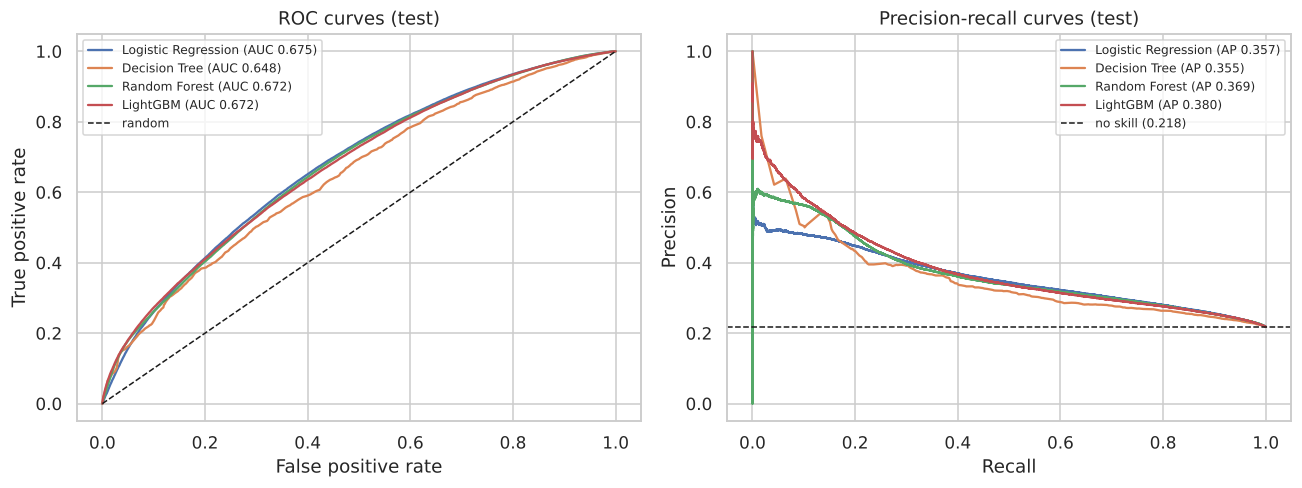

In [29]:
from sklearn.metrics import roc_curve, precision_recall_curve
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
for name, p in test_proba.items():
    if name.startswith("Baseline"): continue
    fpr, tpr, _ = roc_curve(y_test, p); ax[0].plot(fpr, tpr, label=f"{name} (AUC {results.loc[name,'ROC-AUC']:.3f})")
    pr, rc, _ = precision_recall_curve(y_test, p); ax[1].plot(rc, pr, label=f"{name} (AP {results.loc[name,'PR-AUC']:.3f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=1, label="random"); ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("True positive rate"); ax[0].set_title("ROC curves (test)")
ax[1].axhline(y_test.mean(), color="k", ls="--", lw=1, label=f"no skill ({y_test.mean():.3f})")
ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision"); ax[1].set_title("Precision-recall curves (test)")
for a in ax: a.legend(fontsize=8)
plt.tight_layout(); savefig("fig12_roc_pr_curves")

### 5.3 Confusion matrices (at the validation-chosen thresholds)

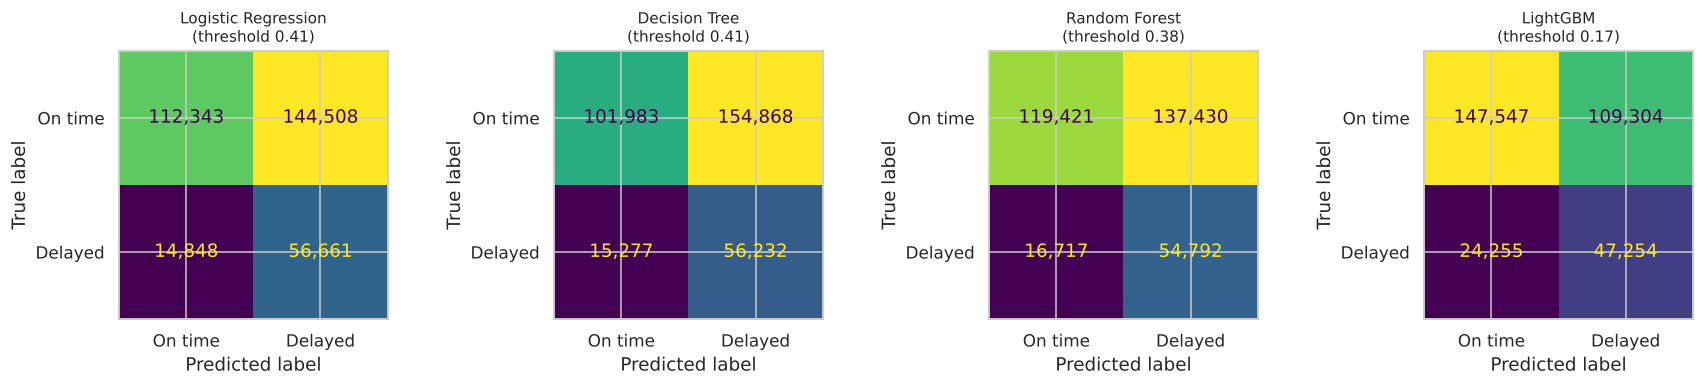

In [30]:
from sklearn.metrics import ConfusionMatrixDisplay
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
for ax, name in zip(axes, fitted):
    ConfusionMatrixDisplay.from_predictions(y_test, test_proba[name] >= thresholds[name], ax=ax, colorbar=False,
                                            display_labels=["On time", "Delayed"], values_format=",")
    ax.set_title(f"{name}\n(threshold {thresholds[name]:.2f})", fontsize=10)
plt.tight_layout(); savefig("fig13_confusion_matrices")

### 5.4 Statistical reliability: bootstrap confidence intervals
Differences of 0.005 in AUC may be noise. The test set is resampled **by day** (block bootstrap, 300 replicates), because flights on the same day are correlated. This gives honest 95 % intervals and a paired comparison of the two best models.

In [31]:
from sklearn.metrics import roc_auc_score, average_precision_score
rng = np.random.default_rng(RANDOM_STATE)
days = test.FL_DATE.values; uniq = np.unique(days)
idx_by_day = {d: np.where(days == d)[0] for d in uniq}
yt = y_test.values
names = list(fitted)
boot = {n: {"ROC-AUC": [], "PR-AUC": []} for n in names}
for b in range(300):
    pick = rng.choice(uniq, size=len(uniq), replace=True)
    idx = np.concatenate([idx_by_day[d] for d in pick])
    for n in names:
        boot[n]["ROC-AUC"].append(roc_auc_score(yt[idx], test_proba[n][idx]))
        boot[n]["PR-AUC"].append(average_precision_score(yt[idx], test_proba[n][idx]))
ci = pd.DataFrame({n: {f"{m} 95% CI": f"[{np.percentile(v,2.5):.3f}, {np.percentile(v,97.5):.3f}]" for m, v in boot[n].items()} for n in names}).T
display(ci)
top2 = results.loc[names, "PR-AUC"].astype(float).nlargest(2).index.tolist()
diff = np.array(boot[top2[0]]["PR-AUC"]) - np.array(boot[top2[1]]["PR-AUC"])
print(f"PR-AUC difference {top2[0]} - {top2[1]}: mean {diff.mean():.4f}, 95% CI [{np.percentile(diff,2.5):.4f}, {np.percentile(diff,97.5):.4f}], "
      f"share of replicates > 0: {(diff > 0).mean():.2f}")

,ROC-AUC 95% CI,PR-AUC 95% CI
Logistic Regression,"[0.632, 0.711]","[0.255, 0.448]"
Decision Tree,"[0.595, 0.691]","[0.228, 0.444]"
Random Forest,"[0.623, 0.714]","[0.245, 0.477]"
LightGBM,"[0.621, 0.717]","[0.253, 0.480]"


PR-AUC difference LightGBM - Random Forest: mean 0.0086, 95% CI [-0.0112, 0.0259], share of replicates > 0: 0.82


### 5.5 Calibration
In operations, the *probability* matters (e.g., "60 % chance of delay"), not just the label, so calibration is checked.

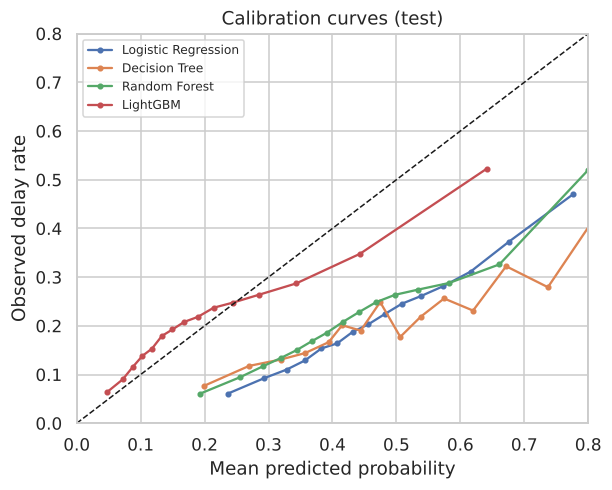

In [32]:
from sklearn.calibration import calibration_curve
fig, ax = plt.subplots(figsize=(6, 4.6))
for name in names:
    fp, mp = calibration_curve(y_test, test_proba[name], n_bins=15, strategy="quantile")
    ax.plot(mp, fp, marker=".", label=name)
ax.plot([0, 1], [0, 1], "k--", lw=1); ax.set_xlabel("Mean predicted probability"); ax.set_ylabel("Observed delay rate")
ax.set_title("Calibration curves (test)"); ax.legend(fontsize=8); ax.set_xlim(0, .8); ax.set_ylim(0, .8)
savefig("fig14_calibration")

### 5.6 Why the temporal split matters: random vs temporal evaluation
The final model's configuration is refitted on a **random** 80/20 split of the same data and compared with the temporal result. This shows how much a naive split would overstate performance.

In [33]:
from sklearn.model_selection import train_test_split
best_name = results.loc[names, "PR-AUC"].astype(float).idxmax()
a, b = train_test_split(data, test_size=0.2, random_state=RANDOM_STATE, stratify=data[TARGET])
a = a.sample(600_000, random_state=RANDOM_STATE)  # keep runtime reasonable
rand_pipe = make_pipeline(best_name, **best_params[best_name]).fit(a[ALL_FEATURES], a[TARGET])
p_rand = rand_pipe.predict_proba(b[ALL_FEATURES])[:, 1]
split_cmp = pd.DataFrame({"Random 80/20 split": [roc_auc_score(b[TARGET], p_rand), average_precision_score(b[TARGET], p_rand)],
                          "Temporal split (test)": [results.loc[best_name, "ROC-AUC"], results.loc[best_name, "PR-AUC"]]},
                         index=["ROC-AUC", "PR-AUC"]).astype(float).round(4)
print("Model:", best_name); split_cmp

Model: LightGBM


,Random 80/20 split,Temporal split (test)
ROC-AUC,0.7610,0.6720
PR-AUC,0.4934,0.3805


### 5.7 Interpretation: what drives the predictions?
**Permutation importance** on the test set measures how much PR-AUC drops when one raw input column is shuffled. Unlike impurity-based importance, it is model-agnostic and is not biased towards high-cardinality features.

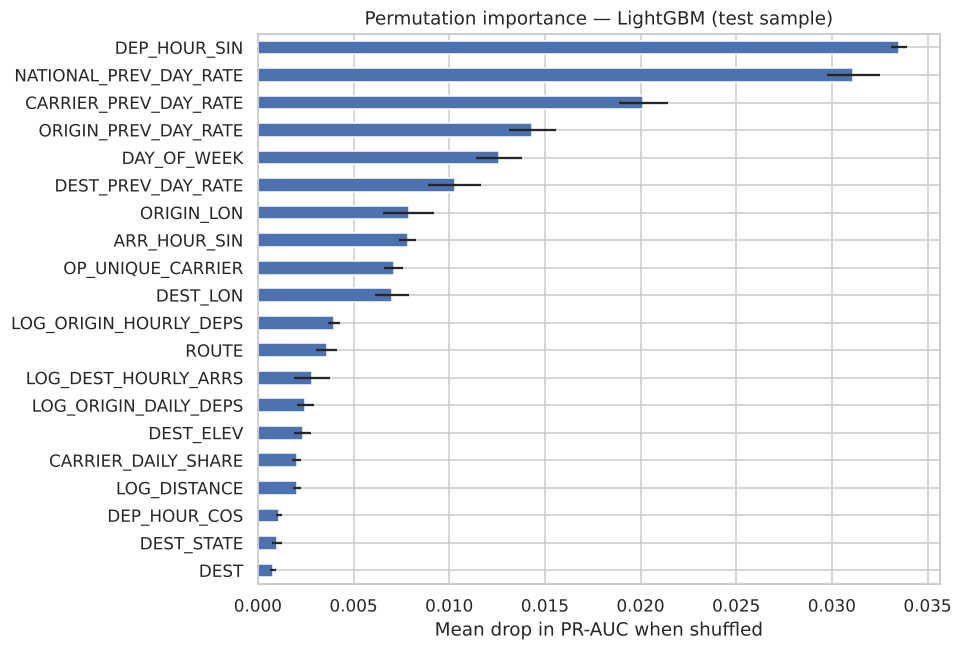

DEP_HOUR_SIN              0.0335
NATIONAL_PREV_DAY_RATE    0.0311
CARRIER_PREV_DAY_RATE     0.0201
ORIGIN_PREV_DAY_RATE      0.0143
DAY_OF_WEEK               0.0126
DEST_PREV_DAY_RATE        0.0103
ORIGIN_LON                0.0079
ARR_HOUR_SIN              0.0078
OP_UNIQUE_CARRIER         0.0071
DEST_LON                  0.0070
dtype: float64

In [34]:
from sklearn.inspection import permutation_importance
final_pipe = fitted[best_name]
Xs = X_test.sample(60_000, random_state=RANDOM_STATE); ys = y_test.loc[Xs.index]
pi = permutation_importance(final_pipe, Xs, ys, scoring="average_precision", n_repeats=3, random_state=RANDOM_STATE, n_jobs=1)
imp = pd.Series(pi.importances_mean, index=ALL_FEATURES).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 6.5))
imp.head(20)[::-1].plot.barh(ax=ax, xerr=pd.Series(pi.importances_std, index=ALL_FEATURES)[imp.head(20).index[::-1]], color="#4C72B0")
ax.set_xlabel("Mean drop in PR-AUC when shuffled"); ax.set_title(f"Permutation importance — {best_name} (test sample)")
savefig("fig15_permutation_importance")
imp.head(10).round(4)

In [35]:
# Logistic regression coefficients (standardised features -> comparable magnitudes)
lr = fitted["Logistic Regression"]
coefs = pd.Series(lr.named_steps["model"].coef_[0], index=lr.named_steps["pre"].get_feature_names_out())
coefs.index = coefs.index.str.replace(r"^(num|low|high)__", "", regex=True)
coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(12).round(3).to_frame("coefficient (log-odds per SD)")

,coefficient (log-odds per SD)
ROUTE,2.981
ORIGIN,0.607
DEST,0.555
OP_UNIQUE_CARRIER_HA,0.384
ORIGIN_STATE,0.324
OP_UNIQUE_CARRIER_YX,-0.322
DEST_STATE,0.284
OP_UNIQUE_CARRIER_UA,-0.234
DEP_TIME_BLOCK_Night(00-05),-0.219
OP_UNIQUE_CARRIER_MQ,-0.216


### 5.8 Error analysis: where does the final model work less well?

,flights,delay_rate,ROC-AUC,recall
OP_UNIQUE_CARRIER,,,,
HA,3676.0,0.229,0.602,0.539
MQ,13091.0,0.225,0.604,0.615
YX,15580.0,0.181,0.626,0.545
OO,38523.0,0.208,0.635,0.701
OH,11628.0,0.267,0.642,0.845
AS,10421.0,0.217,0.642,0.720
UA,36578.0,0.207,0.645,0.575
AA,45026.0,0.254,0.654,0.728
F9,10068.0,0.264,0.673,0.802


,flights,delay_rate,ROC-AUC,recall
DEP_TIME_BLOCK,,,,
Afternoon(12-16),93470.0,0.248,0.646,0.691
Evening(17-20),73980.0,0.302,0.638,0.752
Late(21-23),23214.0,0.280,0.650,0.696
Morning(06-11),126312.0,0.147,0.652,0.520
Night(00-05),11384.0,0.091,0.645,0.329


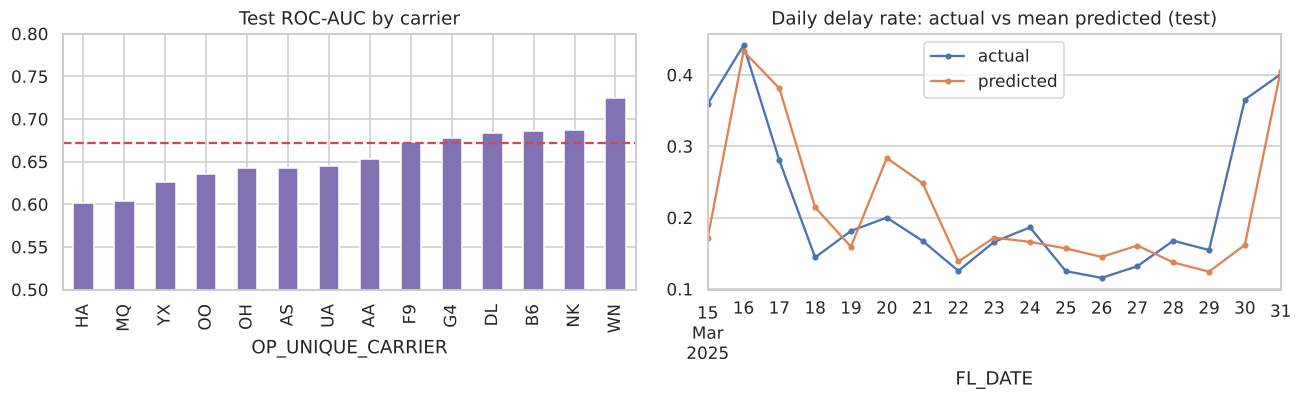

In [36]:
ea = test.assign(p=test_proba[best_name], pred=(test_proba[best_name] >= thresholds[best_name]).astype(int))
def seg(g):
    return pd.Series({"flights": len(g), "delay_rate": g[TARGET].mean(),
                      "ROC-AUC": roc_auc_score(g[TARGET], g.p) if g[TARGET].nunique() > 1 else np.nan,
                      "recall": ((g.pred == 1) & (g[TARGET] == 1)).sum() / max((g[TARGET] == 1).sum(), 1)})
by_carrier = ea.groupby("OP_UNIQUE_CARRIER").apply(seg).sort_values("ROC-AUC")
by_block = ea.groupby("DEP_TIME_BLOCK").apply(seg)
display(by_carrier.round(3)); display(by_block.round(3))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
by_carrier["ROC-AUC"].plot.bar(ax=ax[0], color="#8172B3"); ax[0].axhline(results.loc[best_name,"ROC-AUC"], color="r", ls="--"); ax[0].set_title("Test ROC-AUC by carrier"); ax[0].set_ylim(.5, .8)
dd = ea.groupby("FL_DATE").agg(actual=(TARGET, "mean"), predicted=("p", "mean"))
dd.plot(ax=ax[1], marker="."); ax[1].set_title("Daily delay rate: actual vs mean predicted (test)")
plt.tight_layout(); savefig("fig16_error_analysis")

## 6. Save artefacts for the Streamlit app and the report

In [37]:
import joblib
joblib.dump(final_pipe, MODELS / "final_model.joblib", compress=3)
joblib.dump(fitted["Logistic Regression"], MODELS / "logistic_regression.joblib", compress=3)
meta = {"final_model": best_name, "threshold": thresholds[best_name], "thresholds": thresholds,
        "best_params": {k: {p: (v.item() if hasattr(v, "item") else v) for p, v in d.items()} for k, d in best_params.items()},
        "features": ALL_FEATURES, "numeric": NUMERIC_FEATURES, "low_card": LOW_CARD_CATEGORICAL, "high_card": HIGH_CARD_CATEGORICAL,
        "split": {k: {kk: str(vv) for kk, vv in v.items()} for k, v in split_tbl.T.to_dict().items()},
        "clean_log": clean_log, "fit_seconds": fit_times}
(MODELS / "metadata.json").write_text(json.dumps(meta, indent=2, default=str))
results.astype(float).to_csv(MODELS / "test_metrics.csv")
pd.DataFrame(val_metrics).T.astype(float).to_csv(MODELS / "validation_metrics.csv")
ci.to_csv(MODELS / "bootstrap_ci.csv"); split_cmp.to_csv(MODELS / "split_comparison.csv")
imp.to_csv(MODELS / "permutation_importance.csv")
pd.concat({k: v[["params", "mean_test_score", "rank_test_score"]] for k, v in search_results.items()}).to_csv(MODELS / "search_results.csv")

# test-set predictions (sample) for the evaluation page
pred_sample = test[["FL_DATE", "OP_UNIQUE_CARRIER", "ORIGIN", "DEST", "DEP_HOUR", "DEP_TIME_BLOCK", TARGET]].copy()
for n in names: pred_sample[f"p_{n}"] = test_proba[n]
pred_sample.sample(80_000, random_state=RANDOM_STATE).to_parquet(MODELS / "test_predictions_sample.parquet", index=False)

# processed sample for the app (keeps the repository small enough for Streamlit Cloud)
keep = ["FL_DATE", "MONTH", "DEP_HOUR", "ARR_HOUR", "DISTANCE", "ARR_DELAY", "DAYS_TO_HOLIDAY", "DAY_OF_MONTH",
        "ORIGIN_HOURLY_DEPS", "DEST_HOURLY_ARRS", "ORIGIN_DAILY_DEPS", "CARRIER_NAME", TARGET] + ALL_FEATURES
keep = list(dict.fromkeys(keep))
data[keep].sample(150_000, random_state=RANDOM_STATE).to_parquet(PROC / "flights_sample.parquet", index=False)
airports.to_csv(PROC / "airports_lookup.csv", index=False)
print("Saved:", sorted(p.name for p in MODELS.iterdir()))

Saved: ['bootstrap_ci.csv', 'final_model.joblib', 'logistic_regression.joblib', 'metadata.json', 'permutation_importance.csv', 'search_results.csv', 'split_comparison.csv', 'test_metrics.csv', 'test_predictions_sample.parquet', 'validation_metrics.csv']


## 7. Summary
See the printed tables above for exact values. The conclusions below are discussed in full in the report.
* All four models beat the prior baseline. **LightGBM** is selected as the final model: it has the best test PR-AUC (0.381), precision, specificity and balanced accuracy, and by far the best calibration (Brier 0.160, the only model better than the baseline's 0.171). ROC-AUC is statistically tied between LightGBM, random forest and logistic regression (0.672–0.675; the bootstrap intervals overlap almost completely).
* The single decision tree is the weakest model, as expected from its high variance. Bagging (random forest) and boosting both repair this. Logistic regression is competitive, which shows that much of the signal is roughly additive.
* Performance is **modest** (test ROC-AUC ≈ 0.67) because the largest driver of delays, same-day weather and knock-on disruption, is absent from the schedule data. A random split would have reported ROC-AUC 0.76, an optimistic figure that would not hold up in deployment.
* The most important predictors are the scheduled departure hour and the previous-day disruption rates (national, carrier, origin), followed by weekday, geography and carrier.